 E-COMMERCE CUSTOMER SEGMENTATION & RECOMMENDATION

Original dataset shape: (541909, 8)

First five rows:
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  

Cleaned dataset shape: (392692, 9)
Unique customers: 4338
Unique products: 3665

C

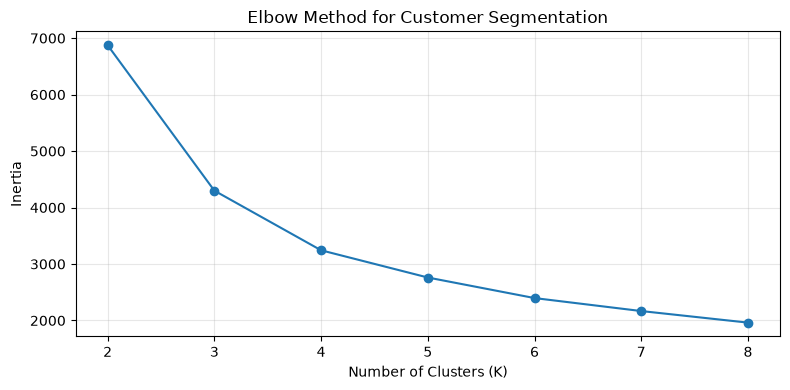


CUSTOMER SEGMENT SUMMARY
-----------------------------------------------------------------
                   Customers  Avg_Recency  Avg_Frequency  Avg_Spending
Segment                                                               
At-Risk Customers        938       259.41           1.37        385.39
Champions                571        19.77          15.84       9823.43
Occasional Buyers       1377        58.04           1.51        384.22
Regular Customers       1452        46.06           4.21       1644.26


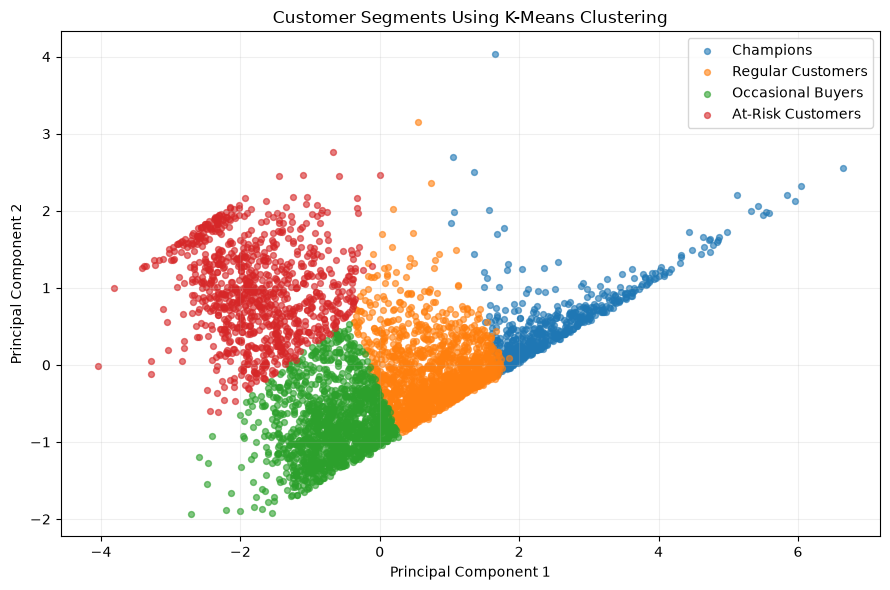

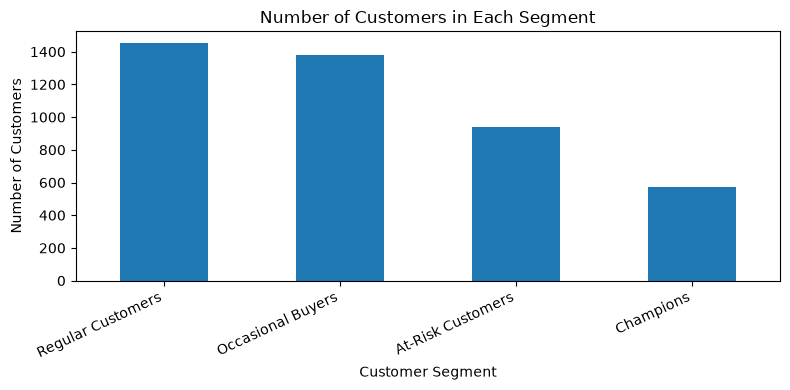


POPULAR PRODUCTS BY CUSTOMER SEGMENT
-----------------------------------------------------------------

 Champions
Description
PAPER CRAFT , LITTLE BIRDIE           80995
JUMBO BAG RED RETROSPOT               34305
WORLD WAR 2 GLIDERS ASSTD DESIGNS     32944
WHITE HANGING HEART T-LIGHT HOLDER    25960
POPCORN HOLDER                        24908

 Regular Customers
Description
MEDIUM CERAMIC TOP STORAGE JAR       74982
WORLD WAR 2 GLIDERS ASSTD DESIGNS    14507
SMALL CHINESE STYLE SCISSOR          12756
ASSORTED COLOUR BIRD ORNAMENT         9129
JUMBO BAG RED RETROSPOT               9061

 Occasional Buyers
Description
POPART WOODEN PENCILS ASST           3300
WORLD WAR 2 GLIDERS ASSTD DESIGNS    2644
BROCADE RING PURSE                   2526
ASSORTED COLOUR BIRD ORNAMENT        2412
JUMBO BAG RED RETROSPOT              2076

 At-Risk Customers
Description
SMALL POPCORN HOLDER                 4681
WORLD WAR 2 GLIDERS ASSTD DESIGNS    4224
ASSORTED COLOURS SILK FAN            2528
RED  

In [2]:

# E-Commerce Customer Segmentation and Recommendation Analysis

import os
import sys
import subprocess
import importlib.util
import zipfile
import urllib.request
import warnings

warnings.filterwarnings("ignore")

# Install required libraries if they are missing
packages = {
    "pandas": "pandas",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "sklearn": "scikit-learn",
    "openpyxl": "openpyxl",
    "scipy": "scipy"
}

for module, package in packages.items():
    if importlib.util.find_spec(module) is None:
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", package]
        )

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse import csr_matrix

print("=" * 65)
print(" E-COMMERCE CUSTOMER SEGMENTATION & RECOMMENDATION")
print("=" * 65)

# 1. Download and load the dataset
file_name = "Online Retail.xlsx"
zip_name = "online_retail.zip"
url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"

try:
    if not os.path.exists(file_name):
        if not os.path.exists(zip_name):
            print("\nDownloading the Online Retail dataset...")
            urllib.request.urlretrieve(url, zip_name)

        with zipfile.ZipFile(zip_name, "r") as file:
            excel_file = next(
                (name for name in file.namelist()
                 if name.lower().endswith(".xlsx")), None
            )
            if excel_file is None:
                raise FileNotFoundError("Excel dataset not found in ZIP.")
            file.extract(excel_file, ".")
            if excel_file != file_name:
                os.replace(excel_file, file_name)

    df = pd.read_excel(file_name)

except Exception as error:
    print("\nAutomatic download failed:", error)
    print("Download Online Retail.xlsx from:")
    print("https://archive.ics.uci.edu/dataset/352/online+retail")
    print("Place the file in your Jupyter Notebook folder and run again.")
    raise

print("\nOriginal dataset shape:", df.shape)
print("\nFirst five rows:")
print(df.head())

# 2. Clean the transaction data
df.columns = df.columns.str.strip()
df = df.drop_duplicates()
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")

df = df.dropna(subset=[
    "CustomerID", "InvoiceNo", "StockCode",
    "Description", "InvoiceDate", "Quantity", "UnitPrice"
])

# Remove cancelled invoices, returns and invalid prices
df = df[~df["InvoiceNo"].astype(str).str.upper().str.startswith("C")]
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]

df["CustomerID"] = df["CustomerID"].astype(int)
df["Sales"] = df["Quantity"] * df["UnitPrice"]
df["Description"] = df["Description"].astype(str).str.strip()

print("\nCleaned dataset shape:", df.shape)
print("Unique customers:", df["CustomerID"].nunique())
print("Unique products:", df["StockCode"].nunique())

# 3. Create customer-level RFM features
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate",
             lambda dates: (reference_date - dates.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Sales", "sum")
)

rfm = rfm.replace([np.inf, -np.inf], np.nan).dropna()
rfm = rfm[(rfm["Frequency"] > 0) & (rfm["Monetary"] > 0)]

print("\nCustomer-level RFM table:")
print(rfm.head())

# 4. Scale the RFM features
# Log transformation reduces the effect of very large purchases
rfm_model = rfm[["Recency", "Frequency", "Monetary"]].copy()
rfm_model["Frequency"] = np.log1p(rfm_model["Frequency"])
rfm_model["Monetary"] = np.log1p(rfm_model["Monetary"])

scaler = StandardScaler()
scaled_features = scaler.fit_transform(rfm_model)

# 5. Elbow method to choose the number of clusters
sample_size = min(10000, len(scaled_features))
rng = np.random.RandomState(42)
sample_indices = rng.choice(
    len(scaled_features), sample_size, replace=False
)
sample_features = scaled_features[sample_indices]

inertia = []
k_values = range(2, 9)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(sample_features)
    inertia.append(model.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(list(k_values), inertia, marker="o")
plt.title("Elbow Method for Customer Segmentation")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Use four interpretable segments for the main analysis
# The elbow plot can be used to discuss this choice.
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm["Cluster"] = kmeans.fit_predict(scaled_features)

# 6. Give customer clusters meaningful names
cluster_profile = rfm.groupby("Cluster")[
    ["Recency", "Frequency", "Monetary"]
].mean()

# A high RFM score means recent, frequent and high-value customers
cluster_profile["RFM_Score"] = (
    cluster_profile["Frequency"].rank(pct=True) +
    cluster_profile["Monetary"].rank(pct=True) +
    (1 - cluster_profile["Recency"].rank(pct=True))
)

# Assign names using cluster behaviour
sorted_clusters = cluster_profile["RFM_Score"].sort_values(
    ascending=False
).index.tolist()

segment_names = {}
segment_names[sorted_clusters[0]] = "Champions"
segment_names[sorted_clusters[1]] = "Regular Customers"
segment_names[sorted_clusters[2]] = "Occasional Buyers"
segment_names[sorted_clusters[3]] = "At-Risk Customers"

rfm["Segment"] = rfm["Cluster"].map(segment_names)

print("\nCUSTOMER SEGMENT SUMMARY")
print("-" * 65)

segment_summary = rfm.groupby("Segment").agg(
    Customers=("Recency", "size"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Spending=("Monetary", "mean")
).round(2)

print(segment_summary)

# 7. Visualize customer clusters using PCA
pca = PCA(n_components=2, random_state=42)
reduced_features = pca.fit_transform(scaled_features)

plot_data = pd.DataFrame({
    "PC1": reduced_features[:, 0],
    "PC2": reduced_features[:, 1],
    "Segment": rfm["Segment"].values
})

plt.figure(figsize=(9, 6))
for segment in segment_names.values():
    part = plot_data[plot_data["Segment"] == segment]
    plt.scatter(
        part["PC1"], part["PC2"],
        label=segment, alpha=0.6, s=18
    )

plt.title("Customer Segments Using K-Means Clustering")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

# 8. Show the number of customers in each segment
plt.figure(figsize=(8, 4))
rfm["Segment"].value_counts().plot(kind="bar")
plt.title("Number of Customers in Each Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

# 9. Create a basic product recommendation system
# Build a sparse customer-product purchase matrix using
# the 300 most frequently purchased products.
top_products = df["StockCode"].value_counts().head(300).index
product_data = df[df["StockCode"].isin(top_products)].copy()

product_data["Product"] = (
    product_data["StockCode"].astype(str) + " - " +
    product_data["Description"]
)

product_list = product_data["Product"].drop_duplicates().tolist()
product_to_index = {p: i for i, p in enumerate(product_list)}

customer_list = rfm.index.tolist()
customer_to_index = {c: i for i, c in enumerate(customer_list)}

product_data = product_data[
    product_data["CustomerID"].isin(customer_to_index)
]

row_indices = product_data["CustomerID"].map(customer_to_index).to_numpy()
col_indices = product_data["Product"].map(product_to_index).to_numpy()
values = product_data["Quantity"].to_numpy(dtype=float)

purchase_matrix = csr_matrix(
    (values, (row_indices, col_indices)),
    shape=(len(customer_list), len(product_list))
)

similarity_matrix = cosine_similarity(
    purchase_matrix.T, dense_output=True
)

# 10. Function to recommend similar products
def recommend_products(product_name, number=5):
    matches = [
        p for p in product_list
        if product_name.lower() in p.lower()
    ]

    if not matches:
        print("Product not found. Try another product name.")
        print("Examples:", product_list[:5])
        return

    selected_product = matches[0]
    product_index = product_to_index[selected_product]

    scores = similarity_matrix[product_index]
    ranked_indices = np.argsort(scores)[::-1]

    recommendations = []
    for idx in ranked_indices:
        if idx != product_index and scores[idx] > 0:
            recommendations.append({
                "Recommended Product": product_list[idx],
                "Similarity Score": round(float(scores[idx]), 3)
            })
        if len(recommendations) >= number:
            break

    print("\nSelected product:", selected_product)
    print("\nRecommended similar products:")
    if recommendations:
        print(pd.DataFrame(recommendations).to_string(index=False))
    else:
        print("No similar products found in this dataset.")

# 11. Show popular products for each customer segment
df["Segment"] = df["CustomerID"].map(rfm["Segment"])
print("\nPOPULAR PRODUCTS BY CUSTOMER SEGMENT")
print("-" * 65)

for segment in segment_names.values():
    segment_products = df[df["Segment"] == segment]
    popular = (
        segment_products.groupby("Description")["Quantity"]
        .sum()
        .sort_values(ascending=False)
        .head(5)
    )

    print("\n", segment)
    print(popular.to_string())

# 12. Export results for the project submission
rfm.to_csv("customer_segments.csv")
segment_summary.to_csv("segment_summary.csv")
df.to_csv("cleaned_retail_transactions.csv", index=False)

print("\nFiles saved:")
print("1. customer_segments.csv")
print("2. segment_summary.csv")
print("3. cleaned_retail_transactions.csv")

# 13. Test the recommendation function
# Change this text to any product name shown in the dataset.
example_product = product_list[0]
recommend_products(example_product, number=5)

print("\n" + "=" * 65)
print("PROJECT ANALYSIS COMPLETED")
print("=" * 65)
print("Customer segmentation, visualizations and recommendations are ready.")
